DATA PREPARATION

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score

In [4]:
data= 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [5]:
df= pd.read_csv(data)
df.to_csv("course_lead_scoring_2026.csv", index=False)

In [6]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [7]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [8]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [9]:
categorical=['lead_source','industry','employment_status','location']
numerical= ['annual_income','number_of_courses_viewed','interaction_count','lead_score']

In [10]:
df[categorical]= df[categorical].fillna('NA')
df[numerical]= df[numerical].fillna(0.0)

In [11]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [12]:
# spllitting the data
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [13]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [14]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

QUESTION 1

In [15]:
for c in ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    print(c, round(auc, 3))

lead_score 0.788
number_of_courses_viewed 0.723
interaction_count 0.765
annual_income 0.608


QUESTION 2

In [16]:
features = categorical + numerical

def train(df_tr, y_tr, C=1.0):
    dicts = df_tr[features].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_tr)
    return dv, model

def predict(df_x, dv, model):
    dicts = df_x[features].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)
print(round(roc_auc_score(y_val, y_pred), 3))

0.732


QUESTION 3

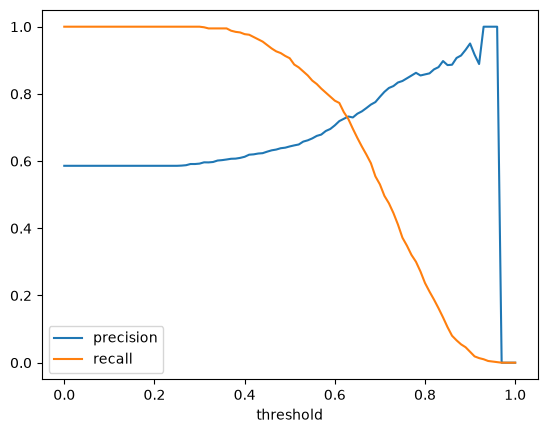

0.63


In [17]:
thresholds = np.arange(0.0, 1.01, 0.01)
rows = []

for t in thresholds:
    pred = y_pred >= t
    tp = (pred & (y_val == 1)).sum()
    fp = (pred & (y_val == 0)).sum()
    fn = (~pred & (y_val == 1)).sum()
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    rows.append((t, p, r))

scores = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall'])

import matplotlib.pyplot as plt
plt.plot(scores.threshold, scores.precision, label='precision')
plt.plot(scores.threshold, scores.recall, label='recall')
plt.legend(); plt.xlabel('threshold'); plt.show()

valid = scores[(scores.precision > 0) | (scores.recall > 0)].copy()
valid['diff'] = (valid.precision - valid.recall).abs()
print(valid.loc[valid['diff'].idxmin(), 'threshold'])

QUESTION 4

In [19]:
scores['f1'] = 2 * scores.precision * scores.recall / (scores.precision + scores.recall)
print(scores.loc[scores.f1.idxmax(), 'threshold'])

0.41000000000000003


QUESTION 5

In [ ]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
aucs = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]
    dv, model = train(df_tr, df_tr.converted.values, C=1.0)
    pred = predict(df_va, dv, model)
    aucs.append(roc_auc_score(df_va.converted.values, pred))

print(round(np.std(aucs), 3))

0.007


QUESTION 6

In [ ]:
for C in [0.000001, 0.001, 1]:
    aucs = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]
        dv, model = train(df_tr, df_tr.converted.values, C=C)
        pred = predict(df_va, dv, model)
        aucs.append(roc_auc_score(df_va.converted.values, pred))
    print(C, round(np.mean(aucs), 3), round(np.std(aucs), 3))

1e-06 0.617 0.019
0.001 0.749 0.01
1 0.732 0.007
